## Import necessary libraries

In [1]:
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision.transforms import functional as TF
from torchvision import datasets, transforms
from torchsummary import summary
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
import torch.nn as nn
import torch
import copy

## Set device

In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cuda


## Hyperparameters

In [3]:
LR = 1e-3
BATCH_SIZE = 128
EPOCHS = 20

##Download data

In [4]:
root = "/content/STL10"

stl10 = datasets.STL10(
    root=root,
    split="unlabeled",
    download=True,
)

## Split data into training, validation and test sets

In [5]:
class ColorizationDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, _ = self.dataset[idx]  # PIL RGB image

        # Target: original RGB image, shape (3, H, W)
        rgb = self.to_tensor(image)

        # Input: grayscale version of the same image, shape (1, H, W)
        grayscale = TF.rgb_to_grayscale(rgb, num_output_channels=1)

        return grayscale, rgb

# Split: 70% / 15% / 15%
total_size = len(stl10)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

generator = torch.Generator().manual_seed(8)

train_set, val_set, test_set = random_split(
    stl10,
    [train_size, val_size, test_size],
    generator=generator,
)

# Wrap each split for grayscale -> RGB learning
train_dataset = ColorizationDataset(train_set)
val_dataset = ColorizationDataset(val_set)
test_dataset = ColorizationDataset(test_set)

# Data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=True,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True,
)

# Verify dataset sizes and tensor shapes
print(f"Train:      {len(train_dataset)}")
print(f"Validation: {len(val_dataset)}")
print(f"Test:       {len(test_dataset)}")

gray_batch, rgb_batch = next(iter(train_loader))
print("Input shape: ", gray_batch.shape)
print("Target shape:", rgb_batch.shape)

Train:      70000
Validation: 15000
Test:       15000
Input shape:  torch.Size([128, 1, 96, 96])
Target shape: torch.Size([128, 3, 96, 96])


## Create model

In [6]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNetColorizer(nn.Module):
    def __init__(self, in_channels=1, out_channels=3, base_channels=32):
        super().__init__()

        c = base_channels

        # Encoder
        self.enc1 = ConvBlock(in_channels, c)       # 96x96
        self.enc2 = ConvBlock(c, c * 2)             # 48x48
        self.enc3 = ConvBlock(c * 2, c * 4)         # 24x24

        self.pool = nn.MaxPool2d(kernel_size=2)

        # Bottleneck
        self.bottleneck = ConvBlock(c * 4, c * 8)   # 12x12

        # Decoder
        self.up3 = nn.ConvTranspose2d(
            c * 8, c * 4, kernel_size=2, stride=2
        )
        self.dec3 = ConvBlock(c * 8, c * 4)         # 24x24

        self.up2 = nn.ConvTranspose2d(
            c * 4, c * 2, kernel_size=2, stride=2
        )
        self.dec2 = ConvBlock(c * 4, c * 2)         # 48x48

        self.up1 = nn.ConvTranspose2d(
            c * 2, c, kernel_size=2, stride=2
        )
        self.dec1 = ConvBlock(c * 2, c)             # 96x96

        # RGB output
        self.final = nn.Conv2d(c, out_channels, kernel_size=1)
        self.activation = nn.Sigmoid()

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)                       # (B, 32, 96, 96)
        e2 = self.enc2(self.pool(e1))           # (B, 64, 48, 48)
        e3 = self.enc3(self.pool(e2))           # (B, 128, 24, 24)

        # Bottleneck
        b = self.bottleneck(self.pool(e3))      # (B, 256, 12, 12)

        # Decoder + skip connections
        d3 = self.up3(b)                        # (B, 128, 24, 24)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)                      # (B, 128, 24, 24)

        d2 = self.up2(d3)                       # (B, 64, 48, 48)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)                      # (B, 64, 48, 48)

        d1 = self.up1(d2)                       # (B, 32, 96, 96)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)                      # (B, 32, 96, 96)

        return self.activation(self.final(d1))  # (B, 3, 96, 96)


model = UNetColorizer(
    in_channels=1,
    out_channels=3,
    base_channels=32
).to(device)

summary(model, input_size=(1, 96, 96))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 96, 96]             320
       BatchNorm2d-2           [-1, 32, 96, 96]              64
              ReLU-3           [-1, 32, 96, 96]               0
            Conv2d-4           [-1, 32, 96, 96]           9,248
       BatchNorm2d-5           [-1, 32, 96, 96]              64
              ReLU-6           [-1, 32, 96, 96]               0
         ConvBlock-7           [-1, 32, 96, 96]               0
         MaxPool2d-8           [-1, 32, 48, 48]               0
            Conv2d-9           [-1, 64, 48, 48]          18,496
      BatchNorm2d-10           [-1, 64, 48, 48]             128
             ReLU-11           [-1, 64, 48, 48]               0
           Conv2d-12           [-1, 64, 48, 48]          36,928
      BatchNorm2d-13           [-1, 64, 48, 48]             128
             ReLU-14           [-1, 64,

## Train model

Epoch 1/20 [Train]:   0%|          | 0/547 [00:00<?, ?it/s]

Epoch 1/20 [Val]:   0%|          | 0/118 [00:00<?, ?it/s]

Epoch [1/20] | Train Loss: 0.05161 | Val Loss: 0.04650


Epoch 2/20 [Train]:   0%|          | 0/547 [00:00<?, ?it/s]

Epoch 2/20 [Val]:   0%|          | 0/118 [00:00<?, ?it/s]

...

Epoch 19/20 [Val]:   0%|          | 0/118 [00:00<?, ?it/s]

Epoch [19/20] | Train Loss: 0.03914 | Val Loss: 0.04073


Epoch 20/20 [Train]:   0%|          | 0/547 [00:00<?, ?it/s]

Epoch 20/20 [Val]:   0%|          | 0/118 [00:00<?, ?it/s]

Epoch [20/20] | Train Loss: 0.03903 | Val Loss: 0.04125
Best validation loss: 0.04039


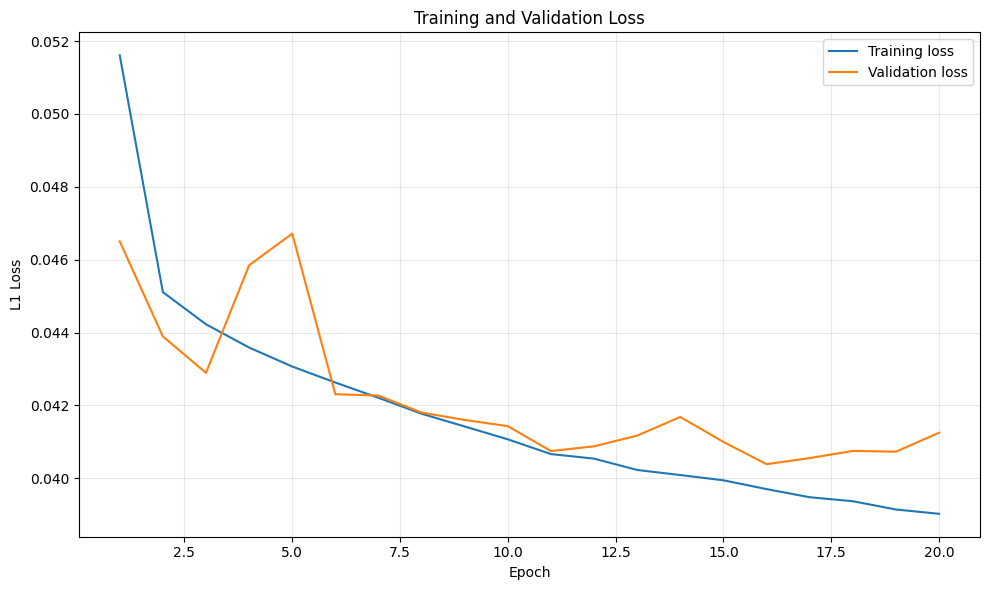

In [7]:
class EarlyStopping:
    def __init__(self, patience=7, min_delta=0.0001):
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.early_stop = False
        self.best_state = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True


# Loss and optimizer
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

early_stopping = EarlyStopping(
    patience=8,
    min_delta=0.0001,
)

training_loss_plot = []
validation_loss_plot = []

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss = 0.0
    train_samples = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS} [Train]"
    )

    for grayscale, rgb in train_bar:
        # Prepare batch
        grayscale = grayscale.to(device, non_blocking=True)
        rgb = rgb.to(device, non_blocking=True)

        # Train
        optimizer.zero_grad(set_to_none=True)

        outputs = model(grayscale)
        loss = criterion(outputs, rgb)

        loss.backward()
        optimizer.step()

        # Stats
        batch_size = grayscale.size(0)
        train_loss += loss.item() * batch_size
        train_samples += batch_size

        train_bar.set_postfix(loss=f"{loss.item():.5f}")

    train_loss /= train_samples
    training_loss_plot.append(train_loss)

    # Validation
    model.eval()
    val_loss = 0.0
    val_samples = 0

    val_bar = tqdm(
        val_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS} [Val]"
    )

    with torch.inference_mode():
        for grayscale, rgb in val_bar:
            # Prepare batch
            grayscale = grayscale.to(device, non_blocking=True)
            rgb = rgb.to(device, non_blocking=True)

            # Validate
            outputs = model(grayscale)
            loss = criterion(outputs, rgb)

            # Stats
            batch_size = grayscale.size(0)
            val_loss += loss.item() * batch_size
            val_samples += batch_size

            val_bar.set_postfix(loss=f"{loss.item():.5f}")

    val_loss /= val_samples
    validation_loss_plot.append(val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f}"
    )

    # Early stopping
    early_stopping(val_loss, model)

    if early_stopping.early_stop:
        print(f"Early stopping after epoch {epoch + 1}.")
        break

# Restore best validation checkpoint
if early_stopping.best_state is not None:
    model.load_state_dict(early_stopping.best_state)
    print(f"Best validation loss: {early_stopping.best_loss:.5f}")

# Plot training progress
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    range(1, len(training_loss_plot) + 1),
    training_loss_plot,
    label="Training loss"
)
ax.plot(
    range(1, len(validation_loss_plot) + 1),
    validation_loss_plot,
    label="Validation loss"
)

ax.set_title("Training and Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("L1 Loss")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Evaluate model

In [8]:
model.eval()
test_loss = 0.0
test_samples = 0

test_bar = tqdm(
    test_loader,
    desc=f"Running evaluation on test set"
)

with torch.inference_mode():
    for grayscale, rgb in test_bar:
        # Prepare batch
        grayscale = grayscale.to(device, non_blocking=True)
        rgb = rgb.to(device, non_blocking=True)

        # Test
        outputs = model(grayscale)
        loss = criterion(outputs, rgb)

        # Stats
        batch_size = grayscale.size(0)
        test_loss += loss.item() * batch_size
        test_samples += batch_size

        test_bar.set_postfix(loss=f"{loss.item():.5f}")

test_loss /= test_samples

print(f"Loss on test dataset: {test_loss:.5f}")

Running evaluation on test set:   0%|          | 0/118 [00:00<?, ?it/s]

Loss on test dataset: 0.03989


## Test model on single samples

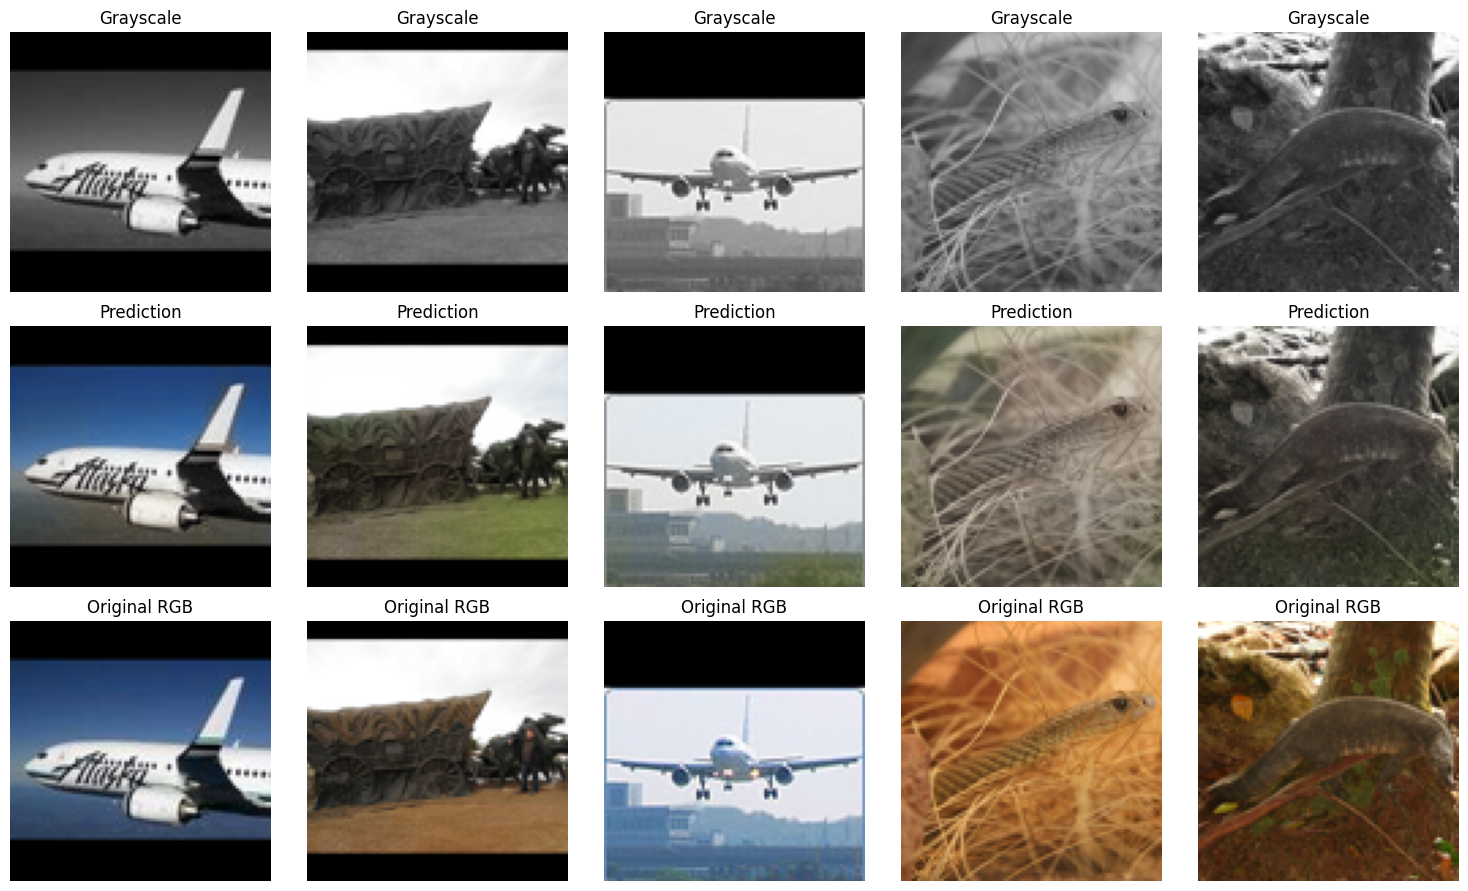

In [9]:
model.eval()

# Number of example predictions
NUM_IMAGES = 5

# Get a batch from the test set
grayscale, rgb = next(iter(test_loader))

grayscale = grayscale[:NUM_IMAGES].to(device)
rgb = rgb[:NUM_IMAGES].to(device)

# Generate predictions
with torch.inference_mode():
    predictions = model(grayscale)

# Move tensors to CPU for visualization
grayscale = grayscale.cpu()
predictions = predictions.cpu().clamp(0, 1)
rgb = rgb.cpu().clamp(0, 1)

# Plot: grayscale / prediction / original RGB
num_images = grayscale.size(0)

fig, axes = plt.subplots(
    3,
    num_images,
    figsize=(3 * num_images, 9),
    squeeze=False
)

for i in range(num_images):
    # Input: grayscale
    axes[0, i].imshow(
        grayscale[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, i].set_title("Grayscale")

    # Model prediction
    axes[1, i].imshow(
        predictions[i].permute(1, 2, 0)
    )
    axes[1, i].set_title("Prediction")

    # Ground truth
    axes[2, i].imshow(
        rgb[i].permute(1, 2, 0)
    )
    axes[2, i].set_title("Original RGB")

    for row in range(3):
        axes[row, i].axis("off")

plt.tight_layout()
plt.show()

## Save model

In [10]:
checkpoint_path = "/content/image_colorizer.pth"

torch.save({
    "model_state_dict": model.state_dict(),
}, checkpoint_path)